# De la exploración a un modelo de pCTR
## Machine Learning en Ads · UBA

**Pregunta:** antes de mostrar un anuncio, ¿qué probabilidad hay de que reciba un clic?
Cada impresión es una observación, `clk ∈ {0, 1}` es la etiqueta y pCTR estima
$P(clk=1\mid x)$. No estamos prediciendo conversiones ni midiendo el efecto causal de mostrar el anuncio.

Reutilizamos los tres CSV y los *left joins* del notebook 01. Ejecutar primero
`python download_data.py` desde la raíz del repositorio. El primer notebook no necesita ejecutarse.
Los datos de Alibaba/Tianchi están licenciados bajo CC BY-NC-SA 4.0 (ver README).

Recorrido: muestreo → split temporal → features → baseline y modelos → umbrales → calibración y segmentos.
La comparación usa **logloss de validación** como criterio principal: queremos probabilidades útiles.

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, precision_recall_curve,
    roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
import sklearn

SEED = 42
SAMPLE_FRACTION = 0.05  # 1.0 usa todo; 0.01 reduce todavía más la memoria
CHUNK_SIZE = 500_000
RUN_LIGHTGBM = True
DATA_DIR = Path('../data/taobao')
assert 0 < SAMPLE_FRACTION <= 1
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})
pd.set_option('display.max_columns', 20)
print('pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('Semilla:', SEED, '| fracción de impresiones:', SAMPLE_FRACTION)

pandas 2.2.3 | sklearn 1.8.0
Semilla: 42 | fracción de impresiones: 0.05


## 1. Una muestra que preserve el problema
Leemos el CSV por bloques para no cargar 26,6 millones de filas antes de muestrear.
Cada impresión se conserva con la misma probabilidad, **independientemente de su etiqueta**.
Usamos la misma regla en los tres períodos: no igualamos positivos y negativos ni hacemos undersampling.
El CTR de evaluación puede diferir ligeramente del 5,14% por azar y por cambios temporales.

Esta muestra no preserva todos los eventos de cada usuario ni los bloques de tres anuncios.
Sirve para comparar modelos sencillos; no para reconstruir historiales completos. La presencia de un
usuario o anuncio en train depende del muestreo, por lo que «nuevo en test» significará nuevo **en esta muestra**.
Para reproducirla se necesitan los CSV con los mismos checksums y orden de filas.

In [2]:
rng = np.random.default_rng(SEED)
parts = []
source_rows = 0
for chunk in pd.read_csv(DATA_DIR / 'raw_sample.csv', chunksize=CHUNK_SIZE,
        dtype={'user': 'int32', 'adgroup_id': 'int32', 'pid': 'category',
               'clk': 'int8', 'nonclk': 'int8'}):
    source_rows += len(chunk)
    keep = rng.random(len(chunk)) < SAMPLE_FRACTION
    parts.append(chunk.loc[keep].copy())
impressions = pd.concat(parts, ignore_index=True)
del parts, chunk
assert impressions['clk'].isin([0, 1]).all()
assert (impressions['clk'] + impressions['nonclk']).eq(1).all()
impressions = impressions.drop(columns='nonclk')
ads = pd.read_csv(DATA_DIR / 'ad_feature.csv')
users = pd.read_csv(DATA_DIR / 'user_profile.csv')
users.columns = users.columns.str.strip()  # espacio final observado en notebook 01
assert ads['adgroup_id'].is_unique and users['userid'].is_unique
print(f'Filas originales: {source_rows:,}; muestra: {len(impressions):,}')
display(pd.DataFrame({'tabla': ['impresiones', 'anuncios', 'usuarios'],
                     'filas': [len(impressions), len(ads), len(users)]}))
print('Columnas reales:', {'ads': list(ads), 'users': list(users)})

Filas originales: 26,557,961; muestra: 1,327,227


,tabla,filas
0,impresiones,1327227
1,anuncios,846811
2,usuarios,1061768


Columnas reales: {'ads': ['adgroup_id', 'cate_id', 'campaign_id', 'customer', 'brand', 'price'], 'users': ['userid', 'cms_segid', 'cms_group_id', 'final_gender_code', 'age_level', 'pvalue_level', 'shopping_level', 'occupation', 'new_user_class_level']}


## 2. Preparación y separación temporal
- **Train:** 6–10 de mayo. Ajustamos transformaciones y pesos del modelo.
- **Validación:** 11–12 de mayo. Elegimos regularización, iteraciones de boosting y umbrales.
- **Test:** 13 de mayo. Evaluación final, sin elegir parámetros a partir de sus resultados.

Todos los horarios se interpretan en `Asia/Shanghai`. A diferencia del split oficial 6–12/13,
reservamos dos días de entrenamiento para validación. No reentrenamos después de elegir modelos,
para mantener coherentes las probabilidades y los umbrales elegidos en validación.

In [3]:
user_cols = [c for c in users if c != 'userid']
users = users.astype(dict.fromkeys(user_cols, 'Int8'))
ads = ads.astype({'cate_id': 'int32', 'campaign_id': 'int32', 'customer': 'int32', 'brand': 'Int32'})
df = (impressions.merge(users, left_on='user', right_on='userid', how='left', validate='many_to_one')
      .drop(columns='userid').merge(ads, on='adgroup_id', how='left', validate='many_to_one'))
assert len(df) == len(impressions)
assert df['cate_id'].notna().all()
del impressions, ads, users
shown_at = pd.to_datetime(df['time_stamp'], unit='s', utc=True).dt.tz_convert('Asia/Shanghai')
assert shown_at.min() >= pd.Timestamp('2017-05-06', tz='Asia/Shanghai')
assert shown_at.max() < pd.Timestamp('2017-05-14', tz='Asia/Shanghai')
df['day'] = shown_at.dt.day.astype('int8')
df['hour'] = shown_at.dt.hour.astype('int8')
assert not df.duplicated(['user', 'adgroup_id', 'time_stamp']).any()
masks = {'train': df.day.between(6, 10), 'valid': df.day.between(11, 12), 'test': df.day.eq(13)}
assert sum(m.astype(int) for m in masks.values()).eq(1).all()
summary = pd.DataFrame({name: {'impresiones': int(m.sum()), 'clics': int(df.loc[m, 'clk'].sum()),
    'CTR': df.loc[m, 'clk'].mean(), 'inicio': shown_at[m].min(), 'fin': shown_at[m].max()}
    for name, m in masks.items()}).T
display(summary)
print(f'Memoria de la tabla unida: {df.memory_usage(deep=True).sum()/1e6:.1f} MB')
print(f'CTR muestra completa: {df.clk.mean():.2%}; accuracy de predecir siempre 0: {1-df.clk.mean():.2%}')

,impresiones,clics,CTR,inicio,fin
train,831179,43198,0.051972,2017-05-06 00:00:00+08:00,2017-05-10 23:59:46+08:00
valid,330705,16803,0.05081,2017-05-11 00:00:00+08:00,2017-05-12 23:59:47+08:00
test,165343,8264,0.049981,2017-05-13 00:00:01+08:00,2017-05-13 23:59:44+08:00


Memoria de la tabla unida: 81.0 MB
CTR muestra completa: 5.14%; accuracy de predecir siempre 0: 94.86%


## 3. Qué se puede conocer antes de la impresión
| Variables | Decisión |
|---|---|
| `pid`, hora | Ubicación y hora conocidas al servir. Hora categórica, sin imponer linealidad. |
| Atributos de usuario | Categorías, incluidos edad y niveles. Ausencia como categoría explícita. |
| `cate_id`, precio, marca faltante | Metadatos del candidato; precio con logaritmo y recorte aprendido en train. |
| `user`, `adgroup_id`, campaña, anunciante, marca ID | Excluidos para controlar cardinalidad y evitar memorizar IDs en esta introducción. IDs solo para diagnosticar segmentos. |
| `clk`, `nonclk` | Etiqueta y su complemento: **nunca features**. |
| CTR por anuncio/usuario calculado en todo el dataset | Leakage directo del futuro y de la propia etiqueta. No se utiliza. |
| Día y timestamp absoluto | Solo split y auditoría; no son features en este ejercicio. |

**Limitación temporal del dataset:** los perfiles y metadatos son snapshots sin fecha de vigencia.
No podemos demostrar que existían así antes de cada impresión. Asumimos su disponibilidad para este
experimento docente; una evaluación operacional necesitaría joins históricos *point-in-time*.

No hacemos target encoding, ni balanceamos clases, ni usamos `class_weight='balanced'`:
esto último cambia el objetivo y puede distorsionar pCTR. Las categorías infrecuentes y desconocidas
se resuelven con un codificador ajustado exclusivamente en train.

In [4]:
cat_cols = ['pid', 'hour', 'cate_id'] + user_cols
num_cols = ['log_price', 'brand_missing', 'profile_missing']
price_cap = df.loc[masks['train'], 'price'].quantile(0.995)
price_fill = df.loc[masks['train'], 'price'].median()
X = df[cat_cols].astype('string').fillna('missing')
X['log_price'] = np.log1p(df['price'].fillna(price_fill).clip(0, price_cap)).astype('float32')
X['brand_missing'] = df['brand'].isna().astype('float32')
X['profile_missing'] = df['cms_group_id'].isna().astype('float32')
assert not set(['clk', 'nonclk', 'day', 'user', 'adgroup_id', 'time_stamp']) & set(X.columns)
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.001,
                          max_categories=128, dtype=np.float32), cat_cols),
    ('num', StandardScaler(), num_cols),
], sparse_threshold=1.0)
Xt = {'train': preprocessor.fit_transform(X.loc[masks['train']])}
for name in ['valid', 'test']:
    Xt[name] = preprocessor.transform(X.loc[masks[name]])
y = {name: df.loc[m, 'clk'].to_numpy() for name, m in masks.items()}
assert all(np.unique(a).size == 2 for a in y.values())
for name, matrix in Xt.items():
    print(name, matrix.shape, f'{(matrix.data.nbytes+matrix.indices.nbytes+matrix.indptr.nbytes)/1e6:.1f} MB sparse')
print(f'Recorte de precio aprendido en train: {price_cap:,.2f}')
del X

train (831179, 252) 96.4 MB sparse
valid (330705, 252) 38.4 MB sparse
test (165343, 252) 19.2 MB sparse
Recorte de precio aprendido en train: 9,140.00


## 4. Baseline y modelos
El baseline predice para todas las impresiones el CTR **de train**. A umbral 0,5 acierta casi
el 95% pero no detecta ningún clic. Es un punto de comparación legítimo para logloss.

La regresión logística aprende efectos aditivos sobre log-odds; usamos one-hot y regularización L2.
Probamos solo dos valores de `C` (menor C = mayor regularización). LightGBM puede aprender interacciones
no lineales. Para que la comparación sea fácil de leer usa la misma matriz dispersa; no es una
optimización exhaustiva ni usa categorías nativas. Limitamos árboles, hojas y cuatro threads.

El test no participa en esta selección. LightGBM es opcional: `RUN_LIGHTGBM=False` omite ese modelo.

In [5]:
train_ctr = float(y['train'].mean())
valid_prob = {'Constante': np.full(len(y['valid']), train_ctr)}
models = {}
trials = []
for C in [0.1, 1.0]:
    start = time.perf_counter()
    model = LogisticRegression(C=C, solver='lbfgs', max_iter=400, tol=1e-5, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(Xt['train'], y['train'])
    p = model.predict_proba(Xt['valid'])[:, 1]
    trials.append({'C': C, 'valid_logloss': log_loss(y['valid'], p),
                   'segundos': time.perf_counter()-start, 'iteraciones': int(model.n_iter_[0])})
    if 'Logística' not in models or trials[-1]['valid_logloss'] < log_loss(y['valid'], valid_prob['Logística']):
        models['Logística'] = model
        valid_prob['Logística'] = p
display(pd.DataFrame(trials))
if RUN_LIGHTGBM:
    import lightgbm as lgb
    print('LightGBM', lgb.__version__)
    start = time.perf_counter()
    model = lgb.LGBMClassifier(n_estimators=250, learning_rate=0.05, num_leaves=15,
        min_child_samples=200, reg_lambda=5, n_jobs=4, random_state=SEED,
        deterministic=True, force_col_wise=True, verbosity=-1)
    model.fit(Xt['train'], y['train'], eval_set=[(Xt['valid'], y['valid'])],
              eval_metric='binary_logloss', callbacks=[lgb.early_stopping(25, verbose=False)])
    models['LightGBM'] = model
    valid_prob['LightGBM'] = model.predict_proba(Xt['valid'])[:, 1]
    print('Árboles elegidos:', model.best_iteration_, '| segundos:', round(time.perf_counter()-start, 1))
validation = pd.DataFrame({name: {'logloss': log_loss(y['valid'], p),
    'ROC-AUC': roc_auc_score(y['valid'], p), 'AP': average_precision_score(y['valid'], p)}
    for name, p in valid_prob.items()}).T
best_name = validation['logloss'].idxmin()
display(validation)
print('Modelo elegido por logloss de validación:', best_name)

,C,valid_logloss,segundos,iteraciones
0,0.1,0.200354,2.829656,101
1,1.0,0.200378,2.647071,93


LightGBM 4.6.0


/workspace/ads-data-course/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Árboles elegidos: 157 | segundos: 4.8


,logloss,ROC-AUC,AP
Constante,0.200906,0.500000,0.050810
Logística,0.200354,0.543996,0.058282
LightGBM,0.200180,0.548155,0.060360


Modelo elegido por logloss de validación: LightGBM


## 5. Probabilidad ≠ decisión: elegir un threshold
Accuracy, precision, recall y F1 requieren una decisión binaria. ROC-AUC mide ordenamiento;
PR-AUC resalta el rendimiento en la clase positiva; logloss penaliza probabilidades incorrectas,
especialmente las confiadas. Aquí reportamos **average precision (AP)** como resumen PR-AUC,
no el área trapezoidal de la curva PR. Su referencia constante es la prevalencia de clics.

Ajustamos un umbral por modelo que maximiza F1 **solo en validación**. Es una decisión didáctica:
en Ads el umbral real depende de costos, valor y restricciones; F1 no expresa rentabilidad.
Para pCTR, el score puede alimentar un ranking o una puja sin convertirlo en 0/1.

,umbral F1 elegido en validación
Constante,0.051972
Logística,0.052951
LightGBM,0.054712


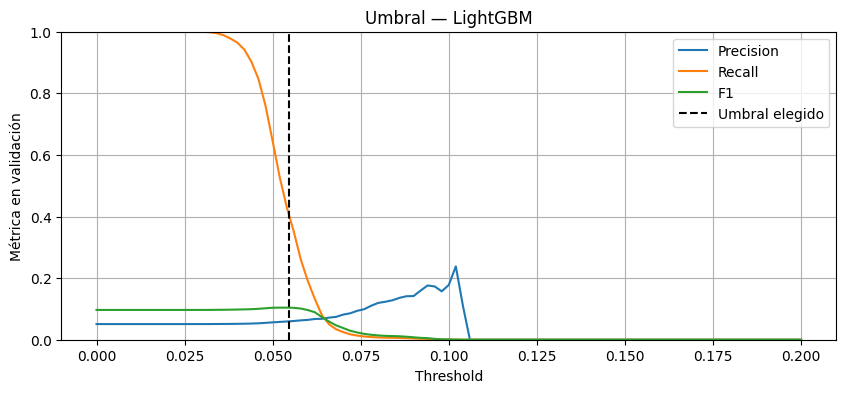

In [6]:
thresholds = {}
for name, p in valid_prob.items():
    precision, recall, ts = precision_recall_curve(y['valid'], p)
    scores = 2*precision[:-1]*recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-15)
    thresholds[name] = float(ts[np.argmax(scores)])
display(pd.Series(thresholds, name='umbral F1 elegido en validación').to_frame())
grid = np.linspace(0, 0.20, 101)
p = valid_prob[best_name]
fig, ax = plt.subplots()
for label, metric in [('Precision', precision_score), ('Recall', recall_score), ('F1', f1_score)]:
    ax.plot(grid, [metric(y['valid'], p >= t, zero_division=0) for t in grid], label=label)
ax.axvline(thresholds[best_name], color='black', ls='--', label='Umbral elegido')
ax.set(xlabel='Threshold', ylabel='Métrica en validación', ylim=(0, 1), title=f'Umbral — {best_name}')
ax.legend(); plt.show()

## 6. Evaluación final en el día reservado
Congelamos modelos y umbrales antes de evaluar test. Mostramos 0,5 y el umbral elegido en validación.
Las métricas de probabilidad no cambian al cambiar el threshold. No reajustaremos modelos a partir
de esta tabla: hacerlo convertiría test en otra validación.

/workspace/ads-data-course/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


threshold  accuracy  precision   recall       F1  ROC-AUC  \
modelo    regla                                                                 
Constante 0.5         0.50000   0.95002    0.00000  0.00000  0.00000  0.50000   
          F1 valid    0.05197   0.04998    0.04998  1.00000  0.09520  0.50000   
Logística 0.5         0.50000   0.95002    0.00000  0.00000  0.00000  0.54823   
          F1 valid    0.05295   0.53339    0.05708  0.53715  0.10320  0.54823   
LightGBM  0.5         0.50000   0.95002    0.00000  0.00000  0.00000  0.54721   
          F1 valid    0.05471   0.64324    0.05921  0.41227  0.10355  0.54721   

                    PR-AUC (AP)  logloss  fracción predicha positiva  
modelo    regla                                                       
Constante 0.5           0.04998  0.19850                     0.00000  
          F1 valid      0.04998  0.19850                     1.00000  
Logística 0.5           0.05848  0.19785                     0.00000  
          F1 valid      0.05848  0.19785                     0.47032  
LightGBM  0.5           0.05860  0.19787                     0.00000  
          F1 valid      0.05860  0.19787                     0.34799

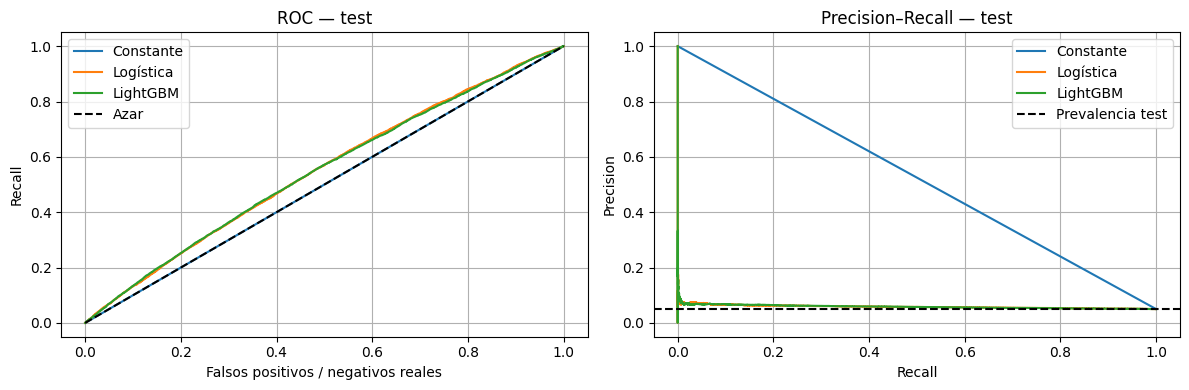

In [7]:
test_prob = {'Constante': np.full(len(y['test']), train_ctr)}
for name, model in models.items():
    test_prob[name] = model.predict_proba(Xt['test'])[:, 1]

def metrics(target, p, threshold):
    pred = p >= threshold
    return {'accuracy': accuracy_score(target, pred),
        'precision': precision_score(target, pred, zero_division=0),
        'recall': recall_score(target, pred, zero_division=0),
        'F1': f1_score(target, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(target, p), 'PR-AUC (AP)': average_precision_score(target, p),
        'logloss': log_loss(target, p), 'fracción predicha positiva': pred.mean()}
rows = []
for name, p in test_prob.items():
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    for rule, threshold in [('0.5', 0.5), ('F1 valid', thresholds[name])]:
        rows.append({'modelo': name, 'regla': rule, 'threshold': threshold, **metrics(y['test'], p, threshold)})
results = pd.DataFrame(rows).set_index(['modelo', 'regla'])
display(results.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, p in test_prob.items():
    fpr, tpr, _ = roc_curve(y['test'], p)
    precision, recall, _ = precision_recall_curve(y['test'], p)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], 'k--', label='Azar')
axes[1].axhline(y['test'].mean(), color='black', ls='--', label='Prevalencia test')
axes[0].set(xlabel='Falsos positivos / negativos reales', ylabel='Recall', title='ROC — test')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall — test')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 7. Calibración: ¿5% significa aproximadamente 5 clics cada 100?
Agrupamos probabilidades en diez intervalos con cantidades similares de ejemplos (cuantiles).
Un modelo calibrado queda cerca de la diagonal. La discriminación puede mejorar sin que mejore
la calibración. Los intervalos vacíos no se dibujan; el baseline tiene un único score.

Reportamos además probabilidad media, CTR observado y Brier score. Una buena coincidencia global
no garantiza calibración por segmento. Estos gráficos diagnostican test: no ajustamos un calibrador
sobre él. Si quisiéramos calibrar, reservaríamos datos temporales adicionales antes del test.

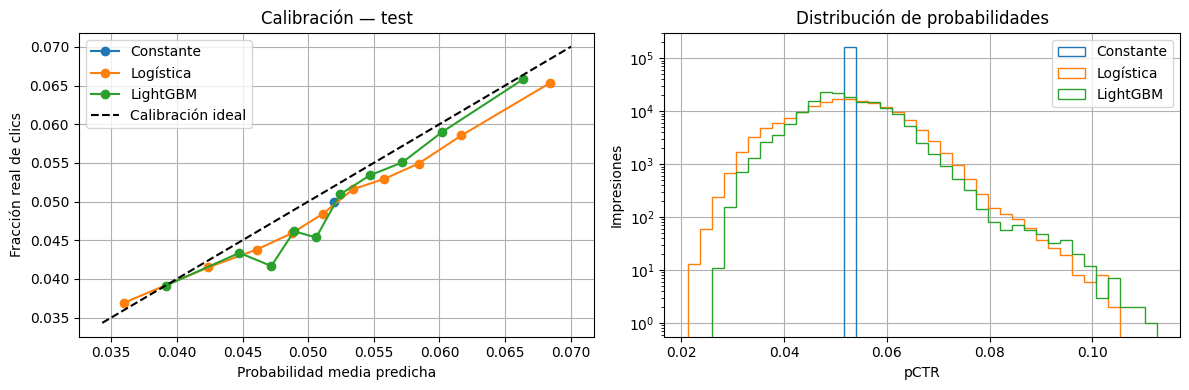

,pCTR media,CTR real,Brier
modelo,,,
Constante,0.051972,0.049981,0.047487
Logística,0.052200,0.049981,0.047425
LightGBM,0.052152,0.049981,0.047425


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cal_rows = []
# Mismos bins para todos: un score constante no debe ampliar el eje artificialmente.
bins = np.linspace(min(p.min() for p in test_prob.values()),
                   max(p.max() for p in test_prob.values()), 40)
for name, p in test_prob.items():
    obs, predicted = calibration_curve(y['test'], p, n_bins=10, strategy='quantile')
    axes[0].plot(predicted, obs, 'o-', label=name)
    axes[1].hist(p, bins=bins, histtype='step', label=name)
    cal_rows.append({'modelo': name, 'pCTR media': p.mean(), 'CTR real': y['test'].mean(),
                     'Brier': brier_score_loss(y['test'], p)})
lo, hi = axes[0].get_xlim()
axes[0].plot([max(0, lo), hi], [max(0, lo), hi], 'k--', label='Calibración ideal')
axes[0].set(xlabel='Probabilidad media predicha', ylabel='Fracción real de clics', title='Calibración — test')
axes[1].set(xlabel='pCTR', ylabel='Impresiones', title='Distribución de probabilidades', yscale='log')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(cal_rows).set_index('modelo'))

## 8. Segmentos: dónde se esconde el promedio
Inspeccionamos el modelo elegido por validación por ubicación, perfil faltante y anuncios
vistos/no vistos en train. Los identificadores se usan para este diagnóstico, nunca para predecir.
Los segmentos pequeños tienen métricas inestables: mostramos denominadores y clics, no solo tasas.
ROC-AUC no está definida si falta una clase. Las diferencias son asociaciones, no efectos causales.
No calculamos intervalos suponiendo impresiones independientes: usuarios y bloques comparten contexto.

,dimensión,segmento,n,clics,CTR,pCTR,sesgo pCTR-CTR,logloss,ROC-AUC
0,pid,430539_1007,61500,3277,0.05328,0.05361,0.00033,0.20736,0.54917
1,pid,430548_1007,103843,4987,0.04802,0.05129,0.00326,0.19225,0.54259
2,perfil,faltante,10252,525,0.05121,0.05250,0.00129,0.20155,0.55252
3,perfil,presente,155091,7739,0.04990,0.05213,0.00223,0.19763,0.54694
4,anuncio,nuevo en muestra,40425,1550,0.03834,0.05182,0.01348,0.16395,0.55630
5,anuncio,visto en train,124918,6714,0.05375,0.05226,-0.00149,0.20885,0.54365


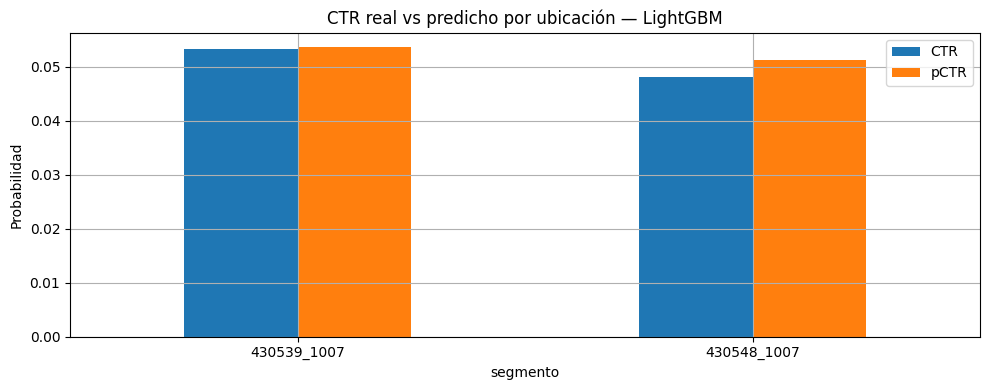

In [9]:
test_rows = df.loc[masks['test'], ['pid', 'adgroup_id', 'cms_group_id', 'clk']].copy()
test_rows['perfil'] = np.where(test_rows.cms_group_id.isna(), 'faltante', 'presente')
test_rows['anuncio'] = np.where(test_rows.adgroup_id.isin(df.loc[masks['train'], 'adgroup_id']),
                                'visto en train', 'nuevo en muestra')
test_rows['p'] = test_prob[best_name]
segments = []
for dimension in ['pid', 'perfil', 'anuncio']:
    for value, group in test_rows.groupby(dimension, observed=True):
        target, p = group.clk.to_numpy(), group.p.to_numpy()
        segments.append({'dimensión': dimension, 'segmento': value, 'n': len(group),
            'clics': int(target.sum()), 'CTR': target.mean(), 'pCTR': p.mean(),
            'sesgo pCTR-CTR': p.mean()-target.mean(), 'logloss': log_loss(target, p, labels=[0, 1]),
            'ROC-AUC': roc_auc_score(target, p) if np.unique(target).size == 2 else np.nan})
segment_table = pd.DataFrame(segments)
display(segment_table.round(5))
placement = segment_table[segment_table['dimensión'].eq('pid')].set_index('segmento')
placement[['CTR', 'pCTR']].plot.bar(rot=0, title=f'CTR real vs predicho por ubicación — {best_name}')
plt.ylabel('Probabilidad'); plt.tight_layout(); plt.show()

## 9. Lectura de los resultados y ejercicios
La celda siguiente resume **esta ejecución**, sin copiar métricas del dataset completo.
Cambiar la muestra cambia los resultados y la definición de anuncios «nuevos».

1. ¿Por qué bajar el threshold mejora recall pero suele reducir precision? Compare ambas reglas.
2. ¿El modelo con mayor ROC-AUC también tiene menor logloss? Explique qué mide cada una.
3. Compare la curva de calibración con el sesgo de cada segmento. ¿Se cancelan errores en el promedio?
4. Como experimento nuevo, reserve otra partición temporal para calibración. No use el test actual para ajustar.
5. ¿Por qué usar el CTR por anuncio calculado con los ocho días sería leakage?
6. Repita con otra semilla como análisis de sensibilidad, sin seleccionar la semilla que mejor rinda en test.

**Alcance:** este es un modelo predictivo sobre anuncios que el sistema histórico decidió mostrar.
No demuestra qué ocurriría al cambiar esa política ni garantiza mejoras de ingresos. No hicimos
búsqueda exhaustiva, intervalos de incertidumbre ni evaluación en múltiples ventanas temporales.

In [10]:
baseline_loss = log_loss(y['test'], test_prob['Constante'])
chosen_loss = log_loss(y['test'], test_prob[best_name])
print(f'Modelo elegido sin mirar test: {best_name}')
print(f'CTR test: {y["test"].mean():.2%}; accuracy siempre no-clic: {1-y["test"].mean():.2%}')
print(f'Logloss test: baseline {baseline_loss:.5f}; elegido {chosen_loss:.5f}')
print(f'Reducción relativa de logloss: {(baseline_loss-chosen_loss)/baseline_loss:.2%}')
print(f'AP test: {average_precision_score(y["test"], test_prob[best_name]):.5f}')
print('Una accuracy alta del baseline no implica identificar clics: su recall a 0.5 es cero.')
print('Revisar tablas y gráficos: mejoras globales pequeñas pueden ocultar errores por segmento.')
print('\nLectura por segmentos del modelo elegido:')
for row in segment_table.itertuples():
    print(f'{row.segmento}: CTR {row.CTR:.2%}, pCTR {row.pCTR:.2%}, n={row.n:,}')
print('La logloss entre segmentos con distinta prevalencia no mide por sí sola cuál es más fácil de ordenar.')
print('El ganador en validación puede no ganar en test: no cambiamos la elección retrospectivamente.')


Modelo elegido sin mirar test: LightGBM
CTR test: 5.00%; accuracy siempre no-clic: 95.00%
Logloss test: baseline 0.19850; elegido 0.19787
Reducción relativa de logloss: 0.32%
AP test: 0.05860
Una accuracy alta del baseline no implica identificar clics: su recall a 0.5 es cero.
Revisar tablas y gráficos: mejoras globales pequeñas pueden ocultar errores por segmento.

Lectura por segmentos del modelo elegido:
430539_1007: CTR 5.33%, pCTR 5.36%, n=61,500
430548_1007: CTR 4.80%, pCTR 5.13%, n=103,843
faltante: CTR 5.12%, pCTR 5.25%, n=10,252
presente: CTR 4.99%, pCTR 5.21%, n=155,091
nuevo en muestra: CTR 3.83%, pCTR 5.18%, n=40,425
visto en train: CTR 5.37%, pCTR 5.23%, n=124,918
La logloss entre segmentos con distinta prevalencia no mide por sí sola cuál es más fácil de ordenar.
El ganador en validación puede no ganar en test: no cambiamos la elección retrospectivamente.


### Observaciones de la corrida guardada (5%, semilla 42)

- El baseline logra **95% de accuracy y recall cero** a umbral 0,5. Es un buen ejemplo de por qué accuracy sola no alcanza.
- LightGBM fue elegido por validación, pero la logística tiene logloss de test ligeramente menor (aprox. 0,19785 vs 0,19787). La diferencia es pequeña; sin incertidumbre ni múltiples ventanas no afirmamos superioridad general.
- Bajar el umbral de LightGBM a aproximadamente 0,0547 lleva recall a 41% y precision a 5,9%: detecta más clics, a costa de muchos falsos positivos. Maximizar F1 no equivale a optimizar negocio.
- Los scores medios rondan 5,22% frente a un CTR real del 5,00%: hay una leve sobreestimación global. En anuncios nuevos **en la muestra**, pCTR ronda 5,18% frente a un CTR de 3,83%, un error mucho mayor que el promedio.
- Las señales usadas mejoran poco la logloss frente al baseline. No debe ocultarse esa mejora modesta: es un punto de partida para estudiar mejores features y evaluación temporal.

Estos valores describen la ejecución guardada, no son constantes del dataset. Las tablas anteriores se recalculan si cambia la configuración.